# Aluno: Breno Alves

# Estudo de Caso MegaTelco - Regressão Logística (treinamento)

## Disciplina: Inteligência Artificial e Aplicações - IIA007
## FATEC Ferraz de Vasconcelos
### Professora: Ana Rosa C. Tonão               
#### Data: 09/11/2026  

---------

## **Descrição dos Dados**


Para este projeto, a MegaTelCo forneceu um conjunto de dados históricos de 14.088 clientes, a partir dos quais já criou dois conjuntos de dados: um conjunto de treino (dataset - churn_hw2_train.xlsx) com 9.856 clientes e um conjunto de teste (dataset - churn_hw2_test.xlsx) com 4.232 clientes.

No momento da coleta dos dados, cada cliente tinha permanecido na empresa ou tinha saído (churned).

Cada cliente é descrito pelas variáveis listadas abaixo:


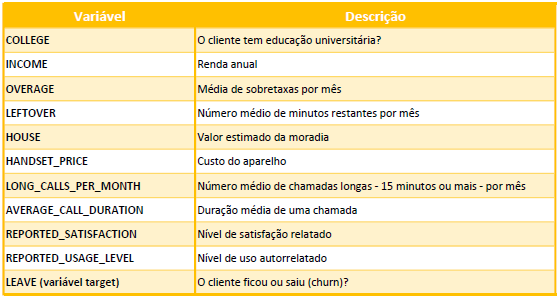

**Fonte**:

FAWCETT,T.;PROVOST,F. **Data Science para Negócios**.Rio de Janeiro, RJ:Alta Books, 2016.
    


## *Preparando o ambiente (Somente VSCODE)*

## *Importando as bibliotecas necessárias*


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import sklearn
from sklearn import linear_model
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

-----
## **(1) Carregando o conjunto de dados (Somente VSCODE)**
-----

### *Carregando os dados de TREINO:*

In [3]:
# Carregando um arquivo de texto separado por ponto e vírgula (.csv)

retention_train = pd.read_csv('retention_train_full_tratado.csv')

### *Carregando os dados de TESTE:*

In [4]:
# Carregando um arquivo de texto separado por ponto e vírgula (.csv)

retention_test = pd.read_csv('retention_test_full_tratado.csv')

-----
## **(2) Inspecionando os dados de TREINO**
-----


In [5]:
# Visualizando os dados carregados - dataset de TREINO
retention_train


,Unnamed: 0,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num,is_outlier
0,0,0,0.746314,-0.885231,0.812636,1.830116,-0.720803,-0.923251,avg,little,actively_looking_into_it,0,3.0,2.0,5.0,False
1,1,1,0.456689,1.520803,-1.140989,-0.621250,-0.837106,-1.151922,very_unsat,very_high,considering,0,1.0,5.0,4.0,False
2,2,0,-0.322444,-0.045028,0.052274,-0.583171,-0.371893,-0.465907,very_sat,very_high,actively_looking_into_it,0,5.0,5.0,5.0,False
3,3,0,1.861229,-0.579703,-0.168746,0.744851,-0.837106,-0.237236,very_unsat,very_little,no,0,1.0,1.0,2.0,False
4,4,0,0.144424,-0.885231,-1.066449,-0.007219,1.488963,2.049482,very_unsat,very_high,actively_looking_into_it,0,1.0,5.0,5.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9848,9851,0,-0.823298,-0.885231,-0.238441,-0.678370,-0.720803,2.049482,very_sat,NaN,actively_looking_into_it,1,5.0,NaN,5.0,False
9849,9852,0,0.695589,-0.426939,0.639115,0.649652,-0.371893,-0.465907,very_unsat,little,considering,1,1.0,2.0,4.0,False
9850,9853,0,-0.887190,0.909747,1.021507,-1.006805,-0.837106,-0.923251,very_unsat,very_little,perhaps,1,1.0,1.0,3.0,False
9851,9854,0,-1.030010,1.444421,-1.114818,-0.873527,-0.720803,-1.151922,unsat,high,no,1,2.0,4.0,2.0,False


In [6]:
retention_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 9853 entries, 0 to 9852
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Unnamed: 0                      9853 non-null   int64  
 1   college                         9853 non-null   int64  
 2   income                          9853 non-null   float64
 3   leftover                        9853 non-null   float64
 4   house                           9853 non-null   float64
 5   handset_price                   9853 non-null   float64
 6   over_15mins_calls_per_month     9853 non-null   float64
 7   average_call_duration           9853 non-null   float64
 8   reported_satisfaction           9848 non-null   str    
 9   reported_usage_level            9849 non-null   str    
 10  considering_change_of_plan      9852 non-null   str    
 11  leave                           9853 non-null   int64  
 12  reported_satisfaction_num       9848 non-null

In [7]:
# Inspecionando o dataframe de TREINO

print("Linhas, colunas: ",retention_train.shape, "\n")

print("Nomes de colunas: ",retention_train.columns, "\n")

print("Índices: ",retention_train.index, "\n")

Linhas, colunas:  (9853, 16) 

Nomes de colunas:  Index(['Unnamed: 0', 'college', 'income', 'leftover', 'house', 'handset_price',
       'over_15mins_calls_per_month', 'average_call_duration',
       'reported_satisfaction', 'reported_usage_level',
       'considering_change_of_plan', 'leave', 'reported_satisfaction_num',
       'reported_usage_level_num', 'considering_change_of_plan_num',
       'is_outlier'],
      dtype='str') 

Índices:  RangeIndex(start=0, stop=9853, step=1) 



-----
## **(3) Inspecionando os dados de TESTE**
-----

In [8]:
# Visualizando os dados carregados - dataset de TESTE

retention_test

,Unnamed: 0,college,income,leftover,house,handset_price,over_15mins_calls_per_month,average_call_duration,reported_satisfaction,reported_usage_level,considering_change_of_plan,leave,reported_satisfaction_num,reported_usage_level_num,considering_change_of_plan_num
0,0,0,1.335304,0.947938,0.454916,1.158965,-0.488196,-0.923251,unsat,high,no,0,2,4,2
1,1,1,-0.675911,-0.388748,0.278064,-0.221416,-0.488196,-0.237236,avg,little,considering,0,3,2,4
2,2,1,-1.015993,-0.885231,1.793362,-0.697409,0.325928,0.448780,very_sat,very_high,considering,0,5,5,4
3,3,0,1.971156,-0.121410,-1.166944,0.635372,-0.720803,-0.465907,very_sat,high,actively_looking_into_it,0,5,4,5
4,4,1,-0.642654,1.024320,-1.265240,0.054660,2.303087,-0.923251,very_unsat,little,considering,0,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4225,4227,0,1.749577,-0.885231,-0.296638,2.410827,-0.371893,2.049482,very_unsat,little,considering,1,1,2,4
4226,4228,1,0.886972,-0.656085,-0.143275,2.063352,1.605266,-0.237236,very_unsat,very_little,no,1,1,1,2
4227,4229,1,-1.239223,1.673567,-0.519498,-1.068684,-0.837106,-0.923251,unsat,very_high,actively_looking_into_it,1,2,5,5
4228,4230,0,-1.403252,2.170050,-0.694152,-0.692649,-0.720803,-0.923251,unsat,little,actively_looking_into_it,1,2,2,5


In [9]:
retention_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 4230 entries, 0 to 4229
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Unnamed: 0                      4230 non-null   int64  
 1   college                         4230 non-null   int64  
 2   income                          4230 non-null   float64
 3   leftover                        4230 non-null   float64
 4   house                           4230 non-null   float64
 5   handset_price                   4230 non-null   float64
 6   over_15mins_calls_per_month     4230 non-null   float64
 7   average_call_duration           4230 non-null   float64
 8   reported_satisfaction           4230 non-null   str    
 9   reported_usage_level            4230 non-null   str    
 10  considering_change_of_plan      4230 non-null   str    
 11  leave                           4230 non-null   int64  
 12  reported_satisfaction_num       4230 non-null

In [10]:
# Inspecionando o dataframe de TESTE

print("Linhas, colunas: ",retention_test.shape, "\n")

print("Nomes de colunas: ",retention_test.columns, "\n")

print("Índices: ",retention_test.index, "\n")

Linhas, colunas:  (4230, 15) 

Nomes de colunas:  Index(['Unnamed: 0', 'college', 'income', 'leftover', 'house', 'handset_price',
       'over_15mins_calls_per_month', 'average_call_duration',
       'reported_satisfaction', 'reported_usage_level',
       'considering_change_of_plan', 'leave', 'reported_satisfaction_num',
       'reported_usage_level_num', 'considering_change_of_plan_num'],
      dtype='str') 

Índices:  RangeIndex(start=0, stop=4230, step=1) 



-----
## **(4) Definindo as amostras de Treino e Teste**
-----

In [11]:
# Definindo a amostra de treino - removemos overage por conta da sua alta correlação
X = retention_train[['income', 'house' ,'handset_price', 'leftover' , 'over_15mins_calls_per_month' , 'average_call_duration']]
Y = retention_train['leave']

In [12]:
# Definindo a amostra de teste - removemos overage por conta da sua alta correlação

Z = retention_test[['income', 'house' ,'handset_price', 'leftover' , 'over_15mins_calls_per_month' , 'average_call_duration']]
W = retention_test['leave']

-----
## **(5) Criando e treinando o classificador**
-----

In [13]:
# Create the logistic regression classifier
classificador = linear_model.LogisticRegression(solver='liblinear', C=1)

# Train the classifier
classificador.fit(X, Y)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penal

-----
## **(6) Realizar a previsão dos clientes que podem deixar a empresa**
-----

### *Aplicando seu modelo aos dados de teste*

In [14]:
# Predict the values for test data
classificador.predict(Z)

array([0, 0, 0, ..., 0, 0, 0], shape=(4230,))

In [15]:
true_labels = W
true_labels

0       0
1       0
2       0
3       0
4       0
       ..
4225    1
4226    1
4227    1
4228    1
4229    1
Name: leave, Length: 4230, dtype: int64

In [16]:
pred_labels = classificador.predict(Z)

pred_labels

array([0, 0, 0, ..., 0, 0, 0], shape=(4230,))

-----
## **(7) Avaliando a qualidade do seu modelo**
-----

### *Criando a matriz de confusão*

In [17]:
# Create confusion matrix

confusion_mat = confusion_matrix(true_labels, pred_labels)

In [18]:
confusion_mat

array([[2884,  170],
       [ 969,  207]])

### *Gerando o classification report*

In [19]:
# Classification report
targets = ['Class-0', 'Class-1']
print('\n', classification_report(true_labels, pred_labels, target_names=targets))


               precision    recall  f1-score   support

     Class-0       0.75      0.94      0.84      3054
     Class-1       0.55      0.18      0.27      1176

    accuracy                           0.73      4230
   macro avg       0.65      0.56      0.55      4230
weighted avg       0.69      0.73      0.68      4230



-----
# **CONCLUSÃO**
-----

Com base nos resultados obtidos no **Classification Report** e na **Matriz de Confusão**, podemos extrair as seguintes conclusões fundamentais sobre a performance inicial do modelo de Regressão Logística:

1. **Acurácia Geral (~73%)**:
   - À primeira vista, uma acurácia de aproximadamente 73% parece satisfatória, mas ela é fortemente influenciada pela predominância da classe majoritária no conjunto de teste (3.054 clientes da classe 0 contra 1.176 da classe 1).

2. **Desempenho por Classe (O Problema do Desbalanceamento)**:
   - **Classe 0 (Clientes que Ficaram)**: Precisão de **75%** e Recall de **94%** (F1-Score: 0.84). O classificador identifica quase todos os clientes que não pretendem sair.
   - **Classe 1 (Clientes que Cancelaram - Churn)**: Precisão de **55%** e Recall de apenas **18%** (F1-Score: 0.27). O modelo sofre com uma **baixa sensibilidade**, detectando corretamente apenas 207 dos 1.176 cancelamentos reais e gerando **969 Falsos Negativos** no limiar padrão (0.50).

3. **Impacto de Negócio para a MegaTelCo**:
   - Em telecomunicações, o custo de perder um cliente (*Falso Negativo*) costuma ser significativamente superior ao custo de ofertar um benefício ou campanha preventiva a quem não iria cancelar (*Falso Positivo*).
   - O limiar padrão de 50% não atende plenamente ao objetivo do negócio, sendo necessária uma exploração da probabilidade predita e calibração de limiares.

4. **Aprofundamento a seguir**:
   - Nas seções abaixo, realizamos a **exploração aprofundada da performance** (Matriz de confusão visual, Curva ROC e AUC, calibração do limiar de corte para aumentar o Recall e análise de Odds Ratios) e efetuamos a **serialização com Pickle** para permitir que o modelo seja reutilizado em novos dados.

-----
## **(8) Exploração Avançada da Performance do Modelo**
-----

Nesta etapa, iremos aprofundar a avaliação do modelo através de:
1. Visualização gráfica detalhada da **Matriz de Confusão** (contagens absolutas e percentuais normalizados);
2. Análise da distribuição de probabilidades e **Curva ROC com métrica AUC**;
3. **Calibração do Limiar de Decisão (Threshold Tuning)** para equilibrar Precisão e Recall conforme a estratégia da MegaTelCo;
4. Avaliação do impacto de cada variável explicativa através dos **Coeficientes e Razão de Chances (Odds Ratio)**.

### *8.1 Visualização da Matriz de Confusão (Absoluta e Normalizada)*

* **Verdadeiros Negativos (VN)**: Clientes que permaneceram e foram corretamente previstos como 0.
* **Falsos Positivos (FP)**: Clientes que permaneceram, mas foram classificados como risco de churn (alarme falso).
* **Falsos Negativos (FN)**: Clientes que cancelaram e o modelo não conseguiu detectar (custo crítico).
* **Verdadeiros Positivos (VP)**: Clientes que cancelaram e foram detectados a tempo pelo modelo.

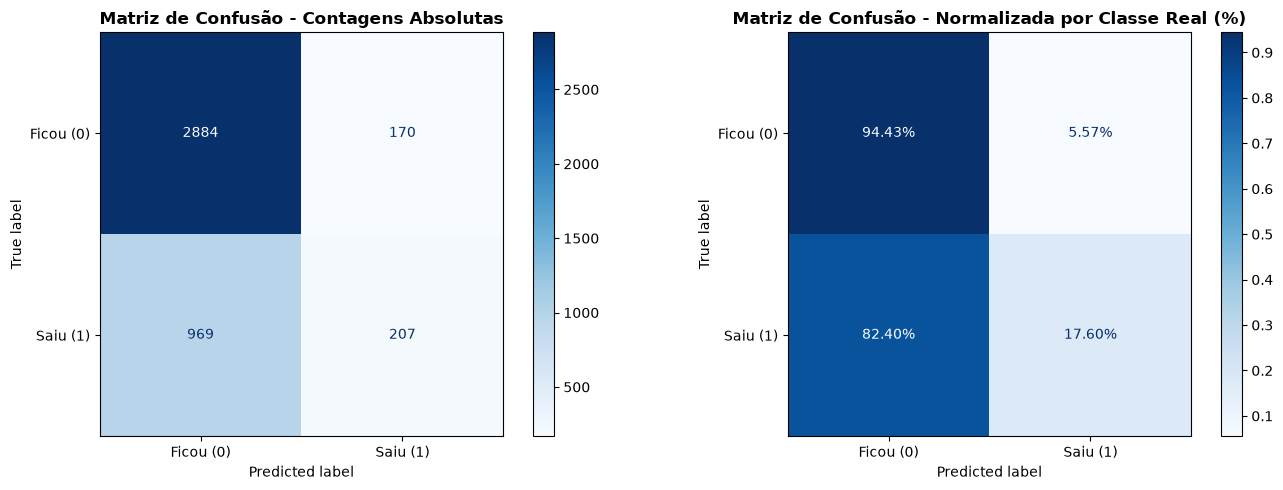

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Matriz de Confusão com contagens absolutas
ConfusionMatrixDisplay.from_predictions(
    true_labels,
    pred_labels,
    display_labels=['Ficou (0)', 'Saiu (1)'],
    cmap='Blues',
    ax=ax[0]
)
ax[0].set_title('Matriz de Confusão - Contagens Absolutas', fontsize=12, fontweight='bold')
ax[0].grid(False)

# 2. Matriz de Confusão normalizada por linha (Recall de cada classe)
ConfusionMatrixDisplay.from_predictions(
    true_labels,
    pred_labels,
    display_labels=['Ficou (0)', 'Saiu (1)'],
    cmap='Blues',
    normalize='true',
    values_format='.2%',
    ax=ax[1]
)
ax[1].set_title('Matriz de Confusão - Normalizada por Classe Real (%)', fontsize=12, fontweight='bold')
ax[1].grid(False)

plt.tight_layout()
plt.show()

### *8.2 Probabilidades Estimadas e Curva ROC (com AUC)*

A regressão logística calcula uma probabilidade $P(Y=1|X) \in [0, 1]$.

A **Curva ROC (Receiver Operating Characteristic)** compara o compromisso entre:
* **Sensibilidade (True Positive Rate - TPR)**: fração de churners reais que o modelo detecta.
* **1 - Especificidade (False Positive Rate - FPR)**: fração de clientes fiéis classificados erroneamente como churn.

A métrica **AUC (Área sob a Curva)** quantifica a capacidade discriminatória geral do classificador (variando de 0.5 a 1.0).

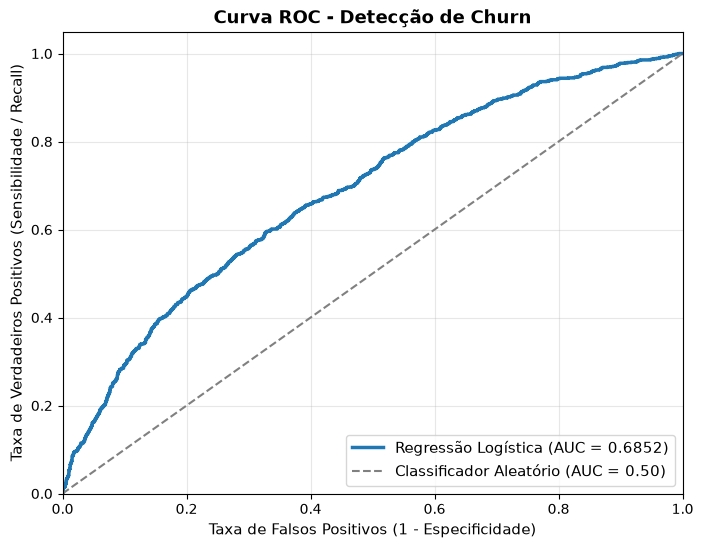

-> Área sob a Curva ROC (AUC-ROC): 0.6852


In [21]:
from sklearn.metrics import roc_curve, roc_auc_score, auc

# Calculando as probabilidades estimadas para a classe positiva (1 = Saiu / Churn)
pred_probs = classificador.predict_proba(Z)[:, 1]

# Cálculo de FPR, TPR e limiares de corte
fpr, tpr, limiares_roc = roc_curve(true_labels, pred_probs)
roc_auc = roc_auc_score(true_labels, pred_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Regressão Logística (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Classificador Aleatório (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=11)
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade / Recall)', fontsize=11)
plt.title('Curva ROC - Detecção de Churn', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()

print(f"-> Área sob a Curva ROC (AUC-ROC): {roc_auc:.4f}")

### *8.3 Ajuste do Limiar de Decisão (Decision Threshold Tuning)*

O método `.predict()` utiliza por padrão o corte de $0.50$ (50% de probabilidade):
$$\hat{y} = 1 \iff P(Y=1|X) \ge 0.50$$

Ao diminuir o limiar (por exemplo, para $0.35$ ou $0.30$), o modelo passa a sinalizar mais clientes em risco de cancelamento, elevando consideravelmente o **Recall** (captura de churners).

In [22]:
# Avaliando o desempenho do modelo sob múltiplos limiares de probabilidade
limiares_teste = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
tabela_limiares = []

for t in limiares_teste:
    pred_t = (pred_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(true_labels, pred_t).ravel()
    
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
    acc = (tp + tn) / len(true_labels)
    
    tabela_limiares.append({
        'Limiar': t,
        'Acurácia': f'{acc:.2%}',
        'Precisão (Churn)': f'{prec:.2%}',
        'Recall (Churn)': f'{rec:.2%}',
        'F1-Score': f'{f1:.4f}',
        'Churns Detectados (VP)': tp,
        'Churns Perdidos (FN)': fn,
        'Alarmes Falsos (FP)': fp
    })

df_tabela_limiares = pd.DataFrame(tabela_limiares)
df_tabela_limiares

,Limiar,Acurácia,Precisão (Churn),Recall (Churn),F1-Score,Churns Detectados (VP),Churns Perdidos (FN),Alarmes Falsos (FP)
0,0.20,50.57%,34.20%,84.18%,0.4864,990,186,1905
1,0.25,57.83%,36.49%,69.81%,0.4793,821,355,1429
2,0.30,65.65%,41.41%,56.80%,0.4790,668,508,945
3,0.35,70.26%,46.38%,44.64%,0.4549,525,651,607
4,0.40,72.34%,50.38%,34.01%,0.4061,400,776,394
5,0.45,73.31%,54.30%,25.26%,0.3447,297,879,250
6,0.50,73.07%,54.91%,17.60%,0.2666,207,969,170
7,0.55,72.96%,56.67%,11.56%,0.1921,136,1040,104
8,0.60,73.22%,65.69%,7.65%,0.1371,90,1086,47


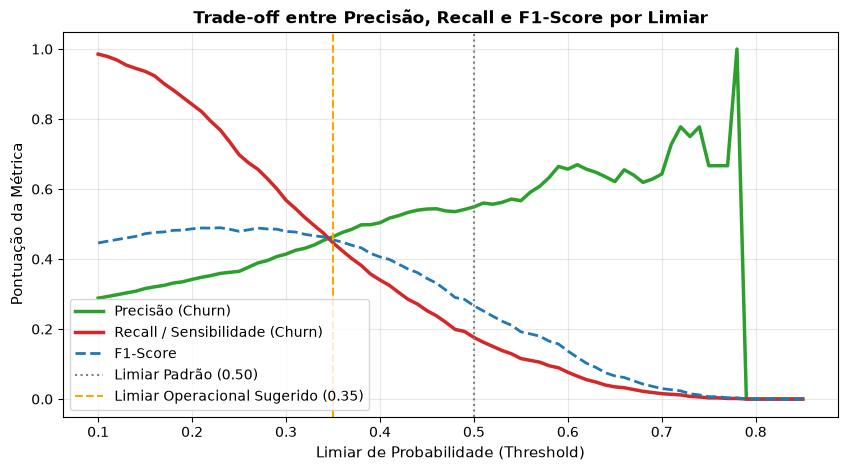

In [23]:
# Visualização gráfica do Trade-off: Precisão vs. Recall vs. F1-Score
pontos_t = np.linspace(0.1, 0.85, 76)
curva_rec, curva_prec, curva_f1 = [], [], []

for t in pontos_t:
    p = (pred_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(true_labels, p).ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
    curva_rec.append(rec)
    curva_prec.append(prec)
    curva_f1.append(f1)

plt.figure(figsize=(10, 5))
plt.plot(pontos_t, curva_prec, label='Precisão (Churn)', color='#2ca02c', lw=2.5)
plt.plot(pontos_t, curva_rec, label='Recall / Sensibilidade (Churn)', color='#d62728', lw=2.5)
plt.plot(pontos_t, curva_f1, label='F1-Score', color='#1f77b4', lw=2, linestyle='--')
plt.axvline(x=0.50, color='gray', linestyle=':', label='Limiar Padrão (0.50)')
plt.axvline(x=0.35, color='orange', linestyle='--', label='Limiar Operacional Sugerido (0.35)')

plt.title('Trade-off entre Precisão, Recall e F1-Score por Limiar', fontsize=12, fontweight='bold')
plt.xlabel('Limiar de Probabilidade (Threshold)', fontsize=11)
plt.ylabel('Pontuação da Métrica', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.show()

### *8.4 Interpretação dos Coeficientes e Razão de Chances (Odds Ratio)*

Na Regressão Logística, a magnitude e o sinal de cada coeficiente $\beta$ explicam a influência da variável na chance de churn:
$$\text{Odds Ratio} = e^{\beta}$$

* $\text{Odds Ratio} > 1$ ($\beta > 0$): O aumento da variável **aumenta** a probabilidade de churn (ex: chamadas longas `over_15mins_calls_per_month`, minutos restantes `leftover`).
* $\text{Odds Ratio} < 1$ ($\beta < 0$): O aumento da variável **reduz** a probabilidade de churn (ex: patrimônio `house`).

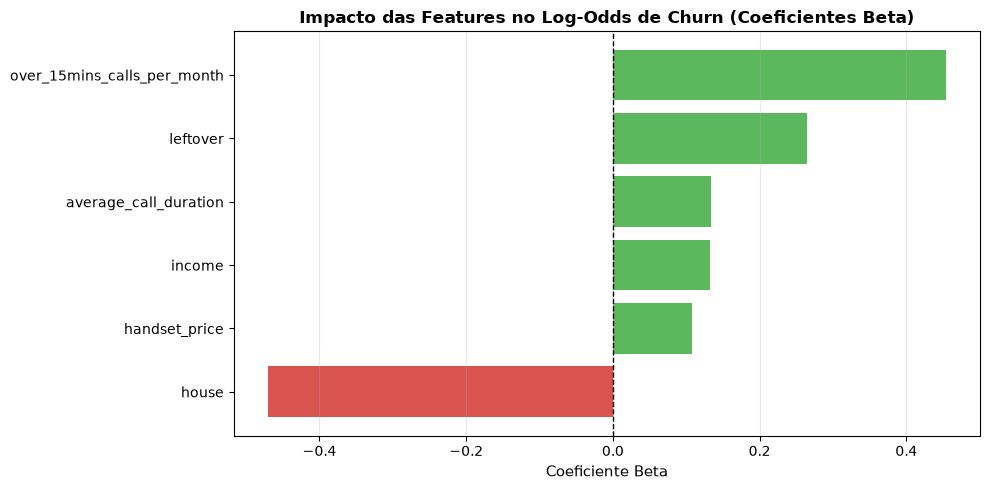

,Feature,Coeficiente (Beta),Odds Ratio (e^Beta)
0,over_15mins_calls_per_month,0.454218,1.574941
1,leftover,0.264381,1.302624
2,average_call_duration,0.133537,1.142863
3,income,0.131893,1.140987
4,handset_price,0.107245,1.113207
5,house,-0.470597,0.624629


In [24]:
# Construção da tabela de coeficientes e Odds Ratio
df_coef = pd.DataFrame({
    'Feature': X.columns,
    'Coeficiente (Beta)': classificador.coef_[0],
    'Odds Ratio (e^Beta)': np.exp(classificador.coef_[0])
}).sort_values(by='Coeficiente (Beta)', ascending=True)

# Plot dos coeficientes
plt.figure(figsize=(10, 5))
cores = ['#d9534f' if b < 0 else '#5cb85c' for b in df_coef['Coeficiente (Beta)']]
plt.barh(df_coef['Feature'], df_coef['Coeficiente (Beta)'], color=cores)
plt.axvline(0, color='black', lw=1, linestyle='--')
plt.title('Impacto das Features no Log-Odds de Churn (Coeficientes Beta)', fontsize=12, fontweight='bold')
plt.xlabel('Coeficiente Beta', fontsize=11)
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

df_coef.sort_values(by='Coeficiente (Beta)', ascending=False).reset_index(drop=True)

-----
## **(9) Salvando e Reutilizando o Modelo com Pickle**
-----

O módulo `pickle` permite persistir o estimador treinado em disco para reutilização futura sem a necessidade de reprocessar os dados e retreinar o algoritmo.

> **Boa prática de Engenharia de Machine Learning**: Em vez de serializar apenas o objeto estimador, encapsulamos também **metadados essenciais para inferência** (ordem das features esperadas, limiar recomendado de negócio e data de geração).

In [25]:
import pickle
from datetime import datetime

# Criando o pacote completo para exportação
artefato_modelo = {
    'modelo': classificador,
    'features': list(X.columns),
    'target': 'leave',
    'algoritmo': 'LogisticRegression(solver=liblinear, C=1)',
    'limiar_recomendado': 0.35,
    'data_treinamento': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

nome_arquivo_pickle = 'modelo_regressao_logistica_churn.pkl'

# Salvando em disco em formato binário (wb = write binary)
with open(nome_arquivo_pickle, 'wb') as arquivo:
    pickle.dump(artefato_modelo, arquivo)

print(f"-> Modelo serializado com sucesso no arquivo: '{nome_arquivo_pickle}'")
print(f"-> Features esperadas salvas no artefato: {artefato_modelo['features']}")
print(f"-> Limiar operacional recomendado: {artefato_modelo['limiar_recomendado']}")

-> Modelo serializado com sucesso no arquivo: 'modelo_regressao_logistica_churn.pkl'
-> Features esperadas salvas no artefato: ['income', 'house', 'handset_price', 'leftover', 'over_15mins_calls_per_month', 'average_call_duration']
-> Limiar operacional recomendado: 0.35


### *9.2 Carregando o Modelo e Realizando Inferência em Novos Dados*

Simulando o consumo do modelo em ambiente de produção: carregamos o arquivo `.pkl` e aplicamos as predições para novos clientes, gerando probabilidades e sugestões de ações para a equipe de retenção.

In [26]:
# 1. Carregando o arquivo serializado (rb = read binary)
with open('modelo_regressao_logistica_churn.pkl', 'rb') as arquivo:
    pacote_carregado = pickle.load(arquivo)

modelo_carregado = pacote_carregado['modelo']
features_modelo = pacote_carregado['features']
limiar_negocio = pacote_carregado['limiar_recomendado']

print("=== Artefato do Modelo Carregado ===")
print(f"Algoritmo: {pacote_carregado['algoritmo']}")
print(f"Data de Geração: {pacote_carregado['data_treinamento']}")
print(f"Features Necessárias: {features_modelo}")
print(f"Limiar de Negócio: {limiar_negocio}\n")

# 2. Simulando novos clientes para escoragem (amostra de teste)
novos_clientes = Z.head(8).copy()

# 3. Estimando probabilidades de churn
probabilidades_churn = modelo_carregado.predict_proba(novos_clientes[features_modelo])[:, 1]

# 4. Classificação com limiar padrão (0.50) e limiar operacional (0.35)
resultado_inferencia = novos_clientes.copy()
resultado_inferencia['Prob_Churn (%)'] = (probabilidades_churn * 100).round(2)
resultado_inferencia['Pred_Padrao_50'] = (probabilidades_churn >= 0.50).astype(int)
resultado_inferencia['Pred_Negocio_35'] = (probabilidades_churn >= limiar_negocio).astype(int)
resultado_inferencia['Acao_Sugerida'] = resultado_inferencia['Pred_Negocio_35'].map({
    0: 'Monitoramento Normal',
    1: 'Acionar Ação de Retenção!'
})

resultado_inferencia[['income', 'house', 'handset_price', 'leftover', 'Prob_Churn (%)', 'Pred_Padrao_50', 'Pred_Negocio_35', 'Acao_Sugerida']]

=== Artefato do Modelo Carregado ===
Algoritmo: LogisticRegression(solver=liblinear, C=1)
Data de Geração: 2026-11-11 21:34:16
Features Necessárias: ['income', 'house', 'handset_price', 'leftover', 'over_15mins_calls_per_month', 'average_call_duration']
Limiar de Negócio: 0.35



,income,house,handset_price,leftover,Prob_Churn (%),Pred_Padrao_50,Pred_Negocio_35,Acao_Sugerida
0,1.335304,0.454916,1.158965,0.947938,25.92,0,0,Monitoramento Normal
1,-0.675911,0.278064,-0.221416,-0.388748,16.22,0,0,Monitoramento Normal
2,-1.015993,1.793362,-0.697409,-0.885231,10.71,0,0,Monitoramento Normal
3,1.971156,-1.166944,0.635372,-0.121410,35.75,0,1,Acionar Ação de Retenção!
4,-0.642654,-1.265240,0.054660,1.024320,66.11,1,1,Acionar Ação de Retenção!
5,-0.877351,-0.216536,-0.802128,-0.885231,29.34,0,0,Monitoramento Normal
6,-0.712254,1.208959,-0.687889,-0.579703,25.85,0,0,Monitoramento Normal
7,1.354374,-1.012568,0.283137,-0.885231,35.25,0,1,Acionar Ação de Retenção!


# ***FIM***